# Exploratory Data Analysis

**Dynamic Pricing Intelligence Platform**

The goal of this notebook is *not* to make pretty charts. It is to answer three
questions that everything downstream depends on:

1. **What does demand actually look like?** Seasonality, day-of-week, booking pace.
2. **Can we learn the price–demand relationship from this data?** (Spoiler: not naively.)
3. **What exactly is the live problem we have to solve?**


In [1]:
import sys
from pathlib import Path


def find_project_root(marker: str = "requirements.txt") -> Path:
    """Walk up from the current directory until we find the project root."""
    path = Path.cwd().resolve()
    for candidate in [path, *path.parents]:
        if (candidate / marker).exists():
            return candidate
    raise RuntimeError(f"Could not find {marker} above {Path.cwd()}")


PROJECT_ROOT = find_project_root()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

REPORTS = PROJECT_ROOT / "reports"
REPORTS.mkdir(exist_ok=True)

print(f"Project root : {PROJECT_ROOT}")
print(f"Reports dir  : {REPORTS}")

Project root : C:\Users\Carlo\OneDrive\Documents\GitHub\hotel-dynamic-pricing
Reports dir  : C:\Users\Carlo\OneDrive\Documents\GitHub\hotel-dynamic-pricing\reports


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sqlalchemy import text

from db import get_engine

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 60)

# "Today" for the whole project. Stay dates after this are still on sale.
TODAY = pd.Timestamp("2026-07-30")

engine = get_engine()
with engine.connect() as conn:
    print("Connected to:", conn.execute(text("SELECT current_database()")).scalar())

Connected to: hotel_pricing


## 1. Load the data

`vw_booking_analysis` is the view we created in Phase 2. It flattens the star
schema and joins `dim_date` twice — once as the stay date, once as the booking
date (the *role-playing dimension* pattern).

Around 680k rows fits comfortably in memory, so we pull it all and work in pandas.

In [3]:
SQL = """
    SELECT hotel_id, hotel_name, city, segment, room_type_id, room_type_name,
           stay_date, booking_date, lead_time, rate, rooms_booked, room_revenue,
           rooms_on_books, rooms_available, occupancy_on_books,
           is_available, is_rate_test,
           stay_day_name, stay_is_weekend, stay_is_holiday, avg_competitor_rate
    FROM pricing.vw_booking_analysis
"""

df = pd.read_sql(text(SQL), engine, parse_dates=["stay_date", "booking_date"])

# NUMERIC columns arrive as Decimal objects, which break arithmetic silently.
for col in ["rate", "room_revenue", "occupancy_on_books", "avg_competitor_rate"]:
    df[col] = df[col].astype(float)

print(f"{len(df):,} rows x {df.shape[1]} columns")
df.head(3)

682,650 rows x 21 columns


,hotel_id,hotel_name,city,segment,room_type_id,room_type_name,stay_date,booking_date,lead_time,rate,rooms_booked,room_revenue,rooms_on_books,rooms_available,occupancy_on_books,is_available,is_rate_test,stay_day_name,stay_is_weekend,stay_is_holiday,avg_competitor_rate
0,HTL001,Harborview Grand,Boston,Business,RT_STD,Standard,2024-08-01,2024-06-03,59,263.69,0,0.0,0,154,0.0,True,False,Thursday,False,False,257.81
1,HTL001,Harborview Grand,Boston,Business,RT_DLX,Deluxe,2024-08-01,2024-06-03,59,355.99,0,0.0,0,48,0.0,True,False,Thursday,False,False,257.81
2,HTL001,Harborview Grand,Boston,Business,RT_STE,Suite,2024-08-01,2024-06-03,59,540.57,0,0.0,0,18,0.0,True,False,Thursday,False,False,257.81


### 1.1 Confirm the grain

Before analysing anything, verify what one row means. If the grain is not what you
think it is, every aggregate below will be wrong.

Our claimed grain: **one row per (hotel, room_type, stay_date, booking_date)**.

In [4]:
grain = ["hotel_id", "room_type_id", "stay_date", "booking_date"]

print("Duplicate rows at claimed grain:", df.duplicated(subset=grain).sum())
print()
print(f"Hotels        : {df['hotel_id'].nunique()}")
print(f"Room types    : {df['room_type_id'].nunique()}")
print(f"Stay dates    : {df['stay_date'].nunique()}")
print(f"Booking window: {df['lead_time'].min()} to {df['lead_time'].max()} days")
print()
print(f"Stay dates    : {df['stay_date'].min().date()} -> {df['stay_date'].max().date()}")
print(f"Booking dates : {df['booking_date'].min().date()} -> {df['booking_date'].max().date()}")
print()
print(f"Closed (past) stay dates : {df.loc[df['stay_date'] <= TODAY, 'stay_date'].nunique()}")
print(f"Open (on sale) stay dates: {df.loc[df['stay_date'] > TODAY, 'stay_date'].nunique()}")

Duplicate rows at claimed grain: 0

Hotels        : 5
Room types    : 3
Stay dates    : 788
Booking window: 0 to 59 days

Stay dates    : 2024-08-01 -> 2026-09-27
Booking dates : 2024-06-03 -> 2026-07-30

Closed (past) stay dates : 729
Open (on sale) stay dates: 59


Note that booking dates start ~60 days *before* the first stay date. That is not a
data error — it is the booking window. Rooms for the first night went on sale two
months earlier.

### 1.2 Data quality

Quick checks for the things that would invalidate the analysis.

In [5]:
checks = {
    "Missing values": df.isna().sum().sum(),
    "Negative rates": (df["rate"] <= 0).sum(),
    "Negative bookings": (df["rooms_booked"] < 0).sum(),
    "Revenue mismatch": (
        (df["room_revenue"] - df["rooms_booked"] * df["rate"]).abs() > 0.01
    ).sum(),
    "On-books exceeds capacity": (df["rooms_on_books"] > df["rooms_available"]).sum(),
}
for label, value in checks.items():
    flag = "OK " if value == 0 else "!! "
    print(f"{flag}{label:<28} {value:,}")

print()
print("Zero-pickup rows:", f"{(df['rooms_booked'] == 0).mean():.1%}")
print("  (expected — most days, most room types take no bookings for a given night)")

OK Missing values               0
OK Negative rates               0
OK Negative bookings            0
OK Revenue mismatch             0
OK On-books exceeds capacity    0

Zero-pickup rows: 59.7%
  (expected — most days, most room types take no bookings for a given night)


## 2. Portfolio KPIs

Three numbers run the hotel industry:

| Metric | Formula | What it tells you |
|---|---|---|
| **ADR** | revenue ÷ rooms sold | how much we charge |
| **Occupancy** | rooms sold ÷ rooms available | how full we are |
| **RevPAR** | revenue ÷ rooms available | the one that matters |

RevPAR = ADR × Occupancy. It is the headline metric because it punishes *both*
failure modes: selling cheap, and leaving rooms empty. Optimising ADR alone leads
to an empty, expensive hotel.

**Critical:** only use *closed* stay dates. Future nights are still filling, and
including them would drag occupancy down for no real reason.

### 2.1 A trap in the aggregation — fan-out

Our fact table has ~60 rows per (hotel, room_type, stay_date), one per booking date.
`rooms_available` is repeated on every one of them.

So `SUM(rooms_available)` **multiplies capacity by 60**. Occupancy comes out around
1.4% and you assume the business is collapsing.

The fix: aggregate to the fact's true grain *first*, taking `max()` of the repeated
dimension attribute, then sum.

In [6]:
closed = df[df["stay_date"] <= TODAY]

# WRONG - fan-out: capacity counted once per booking date
wrong = closed["rooms_booked"].sum() / closed["rooms_available"].sum()

# RIGHT - collapse to (hotel, room_type, stay_date) first
by_night = (
    closed.groupby(["hotel_id", "hotel_name", "segment", "room_type_id", "stay_date"])
    .agg(rooms_sold=("rooms_booked", "sum"),
         revenue=("room_revenue", "sum"),
         capacity=("rooms_available", "max"))     # max, NOT sum
    .reset_index()
)
right = by_night["rooms_sold"].sum() / by_night["capacity"].sum()

print(f"Occupancy with fan-out bug : {wrong:.2%}   <- absurd")
print(f"Occupancy computed properly: {right:.2%}   <- plausible")

Occupancy with fan-out bug : 1.37%   <- absurd
Occupancy computed properly: 82.09%   <- plausible


In [7]:
def kpis(frame, keys):
    """ADR, occupancy and RevPAR from an already-collapsed frame."""
    g = frame.groupby(keys)[["rooms_sold", "revenue", "capacity"]].sum()
    g["adr"] = g["revenue"] / g["rooms_sold"]
    g["occupancy"] = g["rooms_sold"] / g["capacity"]
    g["revpar"] = g["revenue"] / g["capacity"]
    return g.reset_index()


hotel_kpi = kpis(by_night, ["hotel_name", "segment"]).sort_values("revpar", ascending=False)

hotel_kpi.assign(
    revenue_M=lambda x: (x["revenue"] / 1e6).round(2),
    adr=lambda x: x["adr"].round(2),
    occupancy_pct=lambda x: (x["occupancy"] * 100).round(1),
    revpar=lambda x: x["revpar"].round(2),
)[["hotel_name", "segment", "revenue_M", "adr", "occupancy_pct", "revpar"]]

,hotel_name,segment,revenue_M,adr,occupancy_pct,revpar
0,Beachcomber Resort,Leisure,57.24,368.36,82.0,301.97
2,Harborview Grand,Business,40.40,307.09,82.0,251.89
4,Metro Central,Business,28.69,266.21,82.1,218.67
1,Canyon Lodge,Leisure,23.84,248.32,82.3,204.38
3,Lakeside Inn,Mixed,16.61,198.27,82.1,162.70


### Stop and look at that occupancy column.

Five hotels. Five different cities. ADR ranging from $198 to $368. And **every one
of them sits at almost exactly 82% occupancy.**

That is either a bug, or the single most interesting thing in the dataset. Let's
find out which.

## 3. Where did the demand variation go?

If demand genuinely varies by season and day of week, occupancy should move. Let's
plot occupancy by month and by day of week — and then, crucially, **ADR by day of
week alongside it**.

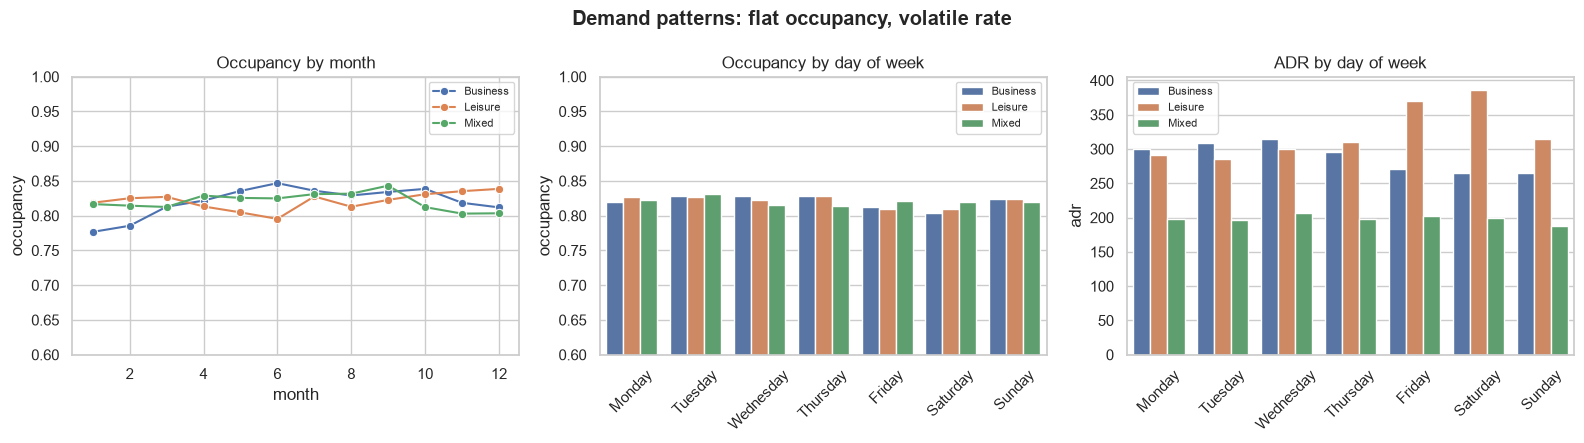

In [8]:
by_night["month"] = by_night["stay_date"].dt.month
by_night["day_name"] = by_night["stay_date"].dt.day_name()

DOW_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday",
             "Friday", "Saturday", "Sunday"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.lineplot(data=kpis(by_night, ["segment", "month"]),
             x="month", y="occupancy", hue="segment", marker="o", ax=axes[0])
axes[0].set_title("Occupancy by month")
axes[0].set_ylim(0.6, 1.0)

sns.barplot(data=kpis(by_night, ["segment", "day_name"]),
            x="day_name", y="occupancy", hue="segment", order=DOW_ORDER, ax=axes[1])
axes[1].set_title("Occupancy by day of week")
axes[1].set_ylim(0.6, 1.0)
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=45)

sns.barplot(data=kpis(by_night, ["segment", "day_name"]),
            x="day_name", y="adr", hue="segment", order=DOW_ORDER, ax=axes[2])
axes[2].set_title("ADR by day of week")
axes[2].set_xlabel("")
axes[2].tick_params(axis="x", rotation=45)

for ax in axes:
    ax.legend(fontsize=8, title=None)

fig.suptitle("Demand patterns: flat occupancy, volatile rate", fontweight="bold")
plt.tight_layout()
fig.savefig(REPORTS / "01_demand_patterns.png", bbox_inches="tight")
plt.show()

In [9]:
# The same finding as numbers, because the chart understates how large it is.
dow = kpis(by_night, ["segment", "day_name"])

print("ADR by day of week")
print(dow.pivot(index="day_name", columns="segment", values="adr")
         .reindex(DOW_ORDER).round(0).to_string())

print("\nOccupancy by day of week")
print(dow.pivot(index="day_name", columns="segment", values="occupancy")
         .reindex(DOW_ORDER).round(3).to_string())

spread = lambda s: (s.max() / s.min() - 1) * 100
print("\nPeak-to-trough spread, Leisure hotels:")
leisure = dow[dow["segment"] == "Leisure"]
print(f"  ADR       : {spread(leisure['adr']):5.1f}%")
print(f"  Occupancy : {spread(leisure['occupancy']):5.1f}%")

ADR by day of week
segment    Business  Leisure  Mixed
day_name                           
Monday        300.0    292.0  199.0
Tuesday       309.0    286.0  197.0
Wednesday     314.0    300.0  206.0
Thursday      296.0    311.0  198.0
Friday        270.0    370.0  203.0
Saturday      264.0    386.0  199.0
Sunday        265.0    315.0  187.0

Occupancy by day of week
segment    Business  Leisure  Mixed
day_name                           
Monday        0.820    0.827  0.823
Tuesday       0.829    0.827  0.832
Wednesday     0.829    0.822  0.816
Thursday      0.828    0.829  0.814
Friday        0.812    0.809  0.821
Saturday      0.804    0.809  0.819
Sunday        0.824    0.824  0.820

Peak-to-trough spread, Leisure hotels:
  ADR       :  35.0%
  Occupancy :   2.5%


### Finding 1 — the legacy system converts demand into rate, not occupancy

Leisure hotels charge **~35% more on Saturday** than midweek. Business hotels
charge ~17% more midweek than at the weekend. But occupancy moves by only a
couple of points.

The demand variation is absolutely there. The legacy pricing rule raises rates on
busy nights until occupancy flattens out — which is precisely what a rate-driven
revenue management system is designed to do.

**This reframes the business problem.** The company is not struggling to fill
rooms. The question is whether 82% is the *right* occupancy — and you cannot
answer that without knowing the price elasticity.

It also plants a warning for Section 5. If price moves almost in lockstep with
demand, how much *independent* price variation is left to learn from?

## 4. Booking curves and pace

Now the structure that makes hotel pricing different from retail. A night is not
sold once — it is sold repeatedly over a 60-day window. **Pickup** is rooms booked
per day; **pace** is how full the night already is.

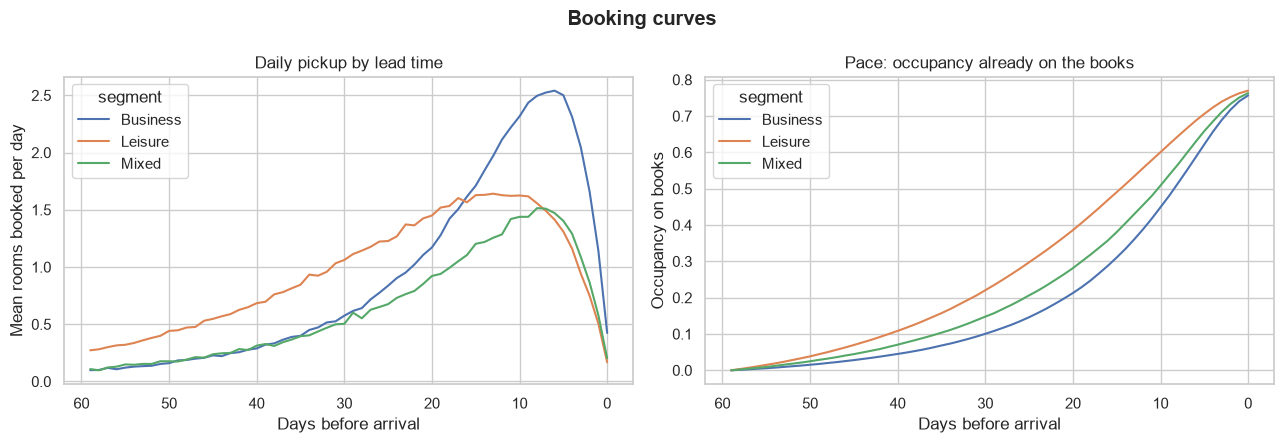

In [10]:
curve = (closed.groupby(["segment", "lead_time"])
         .agg(pickup=("rooms_booked", "mean"),
              on_books=("occupancy_on_books", "mean"))
         .reset_index())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.lineplot(data=curve, x="lead_time", y="pickup", hue="segment", ax=axes[0])
axes[0].invert_xaxis()          # arrival on the right, reads left-to-right in time
axes[0].set_title("Daily pickup by lead time")
axes[0].set_xlabel("Days before arrival")
axes[0].set_ylabel("Mean rooms booked per day")

sns.lineplot(data=curve, x="lead_time", y="on_books", hue="segment", ax=axes[1])
axes[1].invert_xaxis()
axes[1].set_title("Pace: occupancy already on the books")
axes[1].set_xlabel("Days before arrival")
axes[1].set_ylabel("Occupancy on books")

fig.suptitle("Booking curves", fontweight="bold")
plt.tight_layout()
fig.savefig(REPORTS / "02_booking_curves.png", bbox_inches="tight")
plt.show()

In [11]:
# Share of total pickup by lead-time band
bands = pd.cut(closed["lead_time"], [-1, 7, 21, 45, 60],
               labels=["0-7 days", "8-21", "22-45", "46-60"])
pace = (closed.groupby([closed["segment"], bands], observed=True)["rooms_booked"]
        .sum().unstack())
share = (pace.div(pace.sum(axis=1), axis=0) * 100).round(1)
print("Share of pickup by days before arrival")
print(share.to_string())

Share of pickup by days before arrival
lead_time  0-7 days  8-21  22-45  46-60
segment                                
Business       27.7  46.1   22.5    3.7
Leisure        13.5  38.4   38.9    9.3
Mixed          22.0  43.4   28.9    5.7


### Finding 2 — pace means different things by segment

Business hotels take **~28%** of their bookings in the final week. Leisure hotels
take only **~13%**.

The practical consequence for Phase 4: a resort sitting at 40% occupancy 30 days out
is in trouble; a business hotel at the same position is perfectly normal. **Any pace
feature must be relative to that segment's typical curve**, not an absolute number.
A raw `occupancy_on_books` column would tell the model almost nothing on its own.

## 5. The main event — price vs demand

The whole project rests on one relationship: *if we change the rate, what happens
to bookings?*

The naive approach is to plot rate against rooms booked. Let's do it properly —
comparing like with like. Same hotel, same room type, same lead-time band. The
**only** difference between the two panels is how the rate was set:

- **Left:** rates set by the legacy business rule (observational data)
- **Right:** rates set randomly during rate tests (experimental data)

In [12]:
# Hold everything constant except how the price was chosen.
sub = df[
    df["is_available"]                       # room was actually on sale
    & (df["hotel_id"] == "HTL001")
    & (df["room_type_id"] == "RT_STD")
    & df["lead_time"].between(20, 40)
].copy()

print(f"Rows in comparison   : {len(sub):,}")
print(f"Of which rate tests  : {sub['is_rate_test'].sum():,} ({sub['is_rate_test'].mean():.1%})")


def binned_curve(frame, n_bins=12):
    """Average bookings within equal-sized rate buckets."""
    frame = frame.copy()
    frame["rate_bin"] = pd.qcut(frame["rate"], n_bins, duplicates="drop")
    return (frame.groupby("rate_bin", observed=True)
            .agg(rate=("rate", "mean"), booked=("rooms_booked", "mean"))
            .reset_index())


observational = binned_curve(sub)
experimental = binned_curve(sub[sub["is_rate_test"]])

Rows in comparison   : 15,937
Of which rate tests  : 2,118 (13.3%)


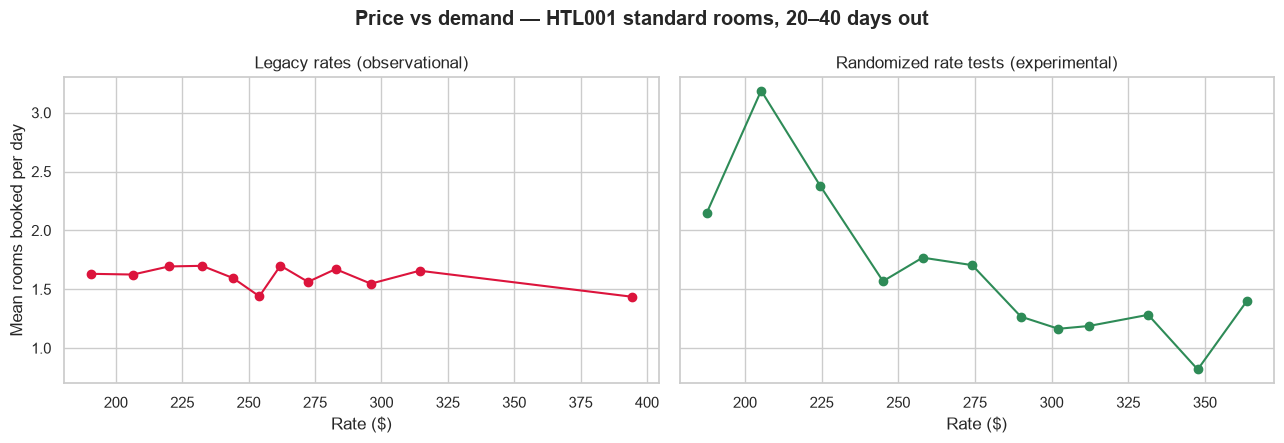

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

axes[0].plot(observational["rate"], observational["booked"], "o-", color="crimson")
axes[0].set_title("Legacy rates (observational)")
axes[0].set_xlabel("Rate ($)")
axes[0].set_ylabel("Mean rooms booked per day")

axes[1].plot(experimental["rate"], experimental["booked"], "o-", color="seagreen")
axes[1].set_title("Randomized rate tests (experimental)")
axes[1].set_xlabel("Rate ($)")

fig.suptitle("Price vs demand — HTL001 standard rooms, 20–40 days out",
             fontweight="bold")
plt.tight_layout()
fig.savefig(REPORTS / "03_price_demand_trap.png", bbox_inches="tight")
plt.show()

In [14]:
# Slope in log-log space is a crude elasticity: % change in bookings
# per % change in rate.
def loglog_slope(binned):
    return np.polyfit(np.log(binned["rate"]),
                      np.log(binned["booked"].clip(lower=0.01)), 1)[0]


print(f"Observational slope : {loglog_slope(observational):+.3f}")
print(f"Experimental slope  : {loglog_slope(experimental):+.3f}")

Observational slope : -0.146
Experimental slope  : -1.476


### Finding 3 — the trap

The left panel is essentially **flat**. An analyst who saw only that would conclude:
*"price barely affects demand — we can raise rates freely."* That conclusion would
be confidently, expensively wrong.

The right panel, using only randomized rates, slopes down hard: roughly **−1.5**.
A 10% rate increase costs about 15% of bookings.

**Why the observational data lies.** Section 3 already told us: the legacy rule
raises price when demand is high. So in the historical data, high prices and high
demand arrive together. That upward confounding almost exactly cancels the true
downward demand response, leaving a flat line.

This is more dangerous than the textbook version of the problem. A *positive* slope
looks obviously broken and gets investigated. A *flat* one looks like a finding.

There is also a perverse implication worth stating in your README: **the better the
old pricing system was, the less your historical data can teach you.** Good rules
destroy the price variation you need to learn from. That is why the ~12% randomized
rate tests exist, and why they carry almost all the information in this dataset.

## 6. Is the experiment actually valid?

Before betting Phase 5 on the rate tests, check they look like a real experiment.

A **balance check** compares treated and untreated groups on *pre-treatment*
characteristics — things fixed before the rate was chosen. If rate-test nights were
systematically more weekend-heavy or holiday-heavy, the randomization would be
broken.

Only ever balance-check pre-treatment variables. Checking outcomes (bookings,
revenue) would be circular.

In [15]:
nights = (closed.groupby(["hotel_id", "stay_date"])
          .agg(is_rate_test=("is_rate_test", "max"),
               is_weekend=("stay_is_weekend", "max"),
               is_holiday=("stay_is_holiday", "max"))
          .reset_index())
nights["month"] = nights["stay_date"].dt.month

balance = nights.groupby("is_rate_test").agg(
    nights=("stay_date", "size"),
    pct_weekend=("is_weekend", "mean"),
    pct_holiday=("is_holiday", "mean"),
    mean_month=("month", "mean"),
).round(3)

print(balance.to_string())
print()
print(f"Rate-test share of stay dates: {nights['is_rate_test'].mean():.1%}")

              nights  pct_weekend  pct_holiday  mean_month
is_rate_test                                              
False           3190        0.281        0.029       6.531
True             455        0.319        0.042       6.484

Rate-test share of stay dates: 12.5%


### Finding 4 — the randomization holds

Weekend share, holiday share and seasonal spread are close between the two groups.
The rate tests behave like a genuine experiment, so we are entitled to treat them
as one in Phase 5.

*(A more rigorous version would report standardised differences or a joint test.
For a portfolio project, showing that you knew to check at all is the point.)*

## 7. Competitive positioning

Competitor rates matter twice: as a **business** signal, and as a **statistical
control** in Phase 5 (they move with market demand, so they proxy for it).

One caveat that matters: competitor rates in our data are quoted at *hotel* level —
effectively a standard-room benchmark. Comparing a suite rate against them is
meaningless, so we restrict to `RT_STD`.

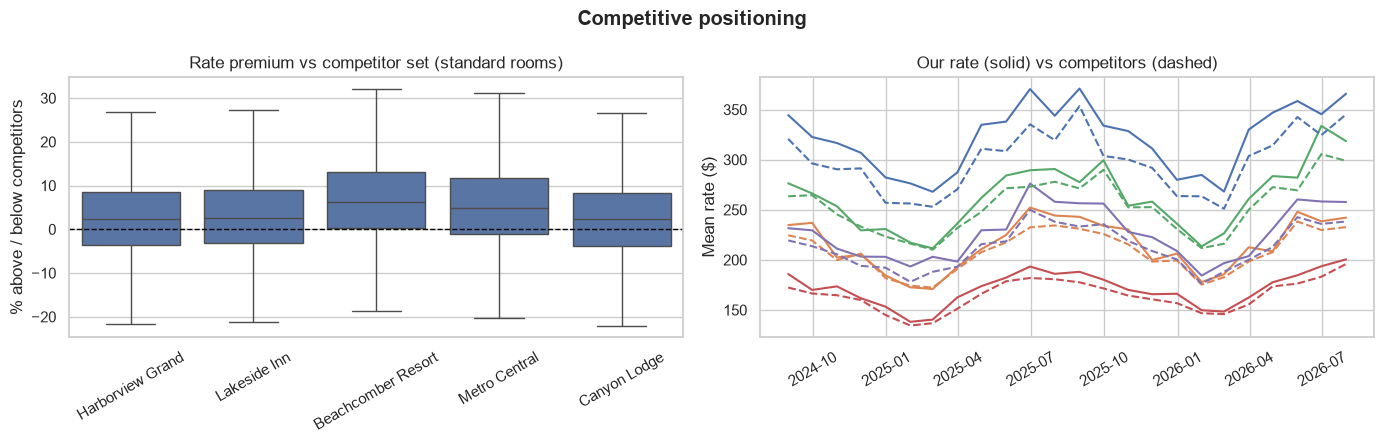

                    mean  50%   std
hotel_name                         
Beachcomber Resort   7.5  6.3  12.9
Canyon Lodge         2.9  2.4  11.2
Harborview Grand     3.3  2.3  11.7
Lakeside Inn         4.1  2.6  12.4
Metro Central        6.2  4.8  11.9


In [16]:
std = closed[closed["room_type_id"] == "RT_STD"].copy()
std["gap_pct"] = (std["rate"] / std["avg_competitor_rate"] - 1) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.boxplot(data=std, x="hotel_name", y="gap_pct", ax=axes[0], showfliers=False)
axes[0].axhline(0, color="black", lw=1, ls="--")
axes[0].set_title("Rate premium vs competitor set (standard rooms)")
axes[0].set_ylabel("% above / below competitors")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=30)

monthly = (std.set_index("stay_date")
           .groupby([pd.Grouper(freq="ME"), "hotel_name"])
           [["rate", "avg_competitor_rate"]].mean().reset_index())
sns.lineplot(data=monthly, x="stay_date", y="rate", hue="hotel_name",
             ax=axes[1], legend=False)
sns.lineplot(data=monthly, x="stay_date", y="avg_competitor_rate",
             hue="hotel_name", ax=axes[1], ls="--", legend=False)
axes[1].set_title("Our rate (solid) vs competitors (dashed)")
axes[1].set_xlabel("")
axes[1].set_ylabel("Mean rate ($)")
axes[1].tick_params(axis="x", rotation=30)

fig.suptitle("Competitive positioning", fontweight="bold")
plt.tight_layout()
fig.savefig(REPORTS / "04_competitor_positioning.png", bbox_inches="tight")
plt.show()

print(std.groupby("hotel_name")["gap_pct"].describe()[["mean", "50%", "std"]].round(1).to_string())

## 8. The live pricing problem

The last 60 stay dates are still on sale. This is not a backtest — these nights are
genuinely unsold, and Phases 5–6 have to decide what to charge for them.

For each open night we take the **most recent** snapshot: the current rate and how
many rooms are already on the books.

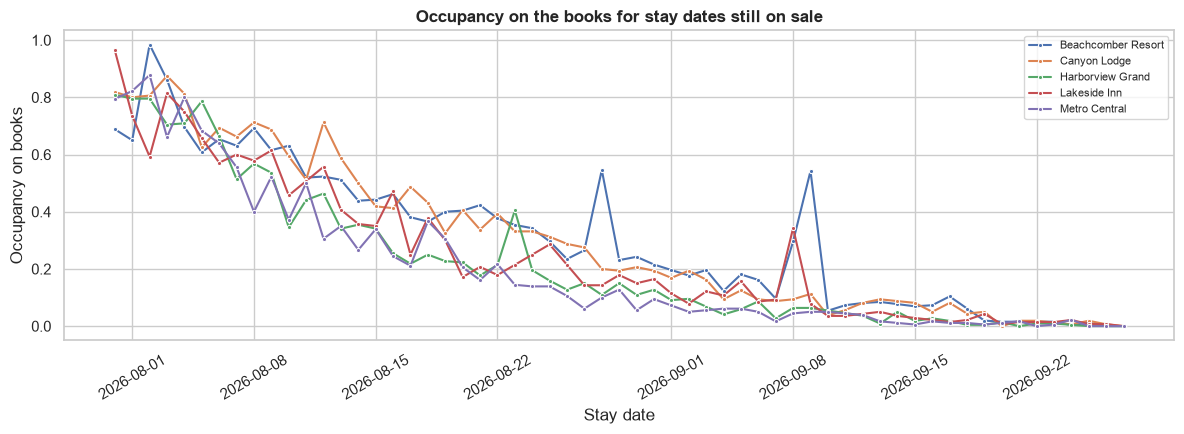

Open stay dates    : 59
Mean occupancy     : 25.9%
Rooms still unsold : 41,816
Revenue at stake   : $17,473,378


In [17]:
open_nights = df[df["stay_date"] > TODAY]

# Latest observation per (hotel, room type, stay date)
latest = (open_nights.sort_values("booking_date")
          .groupby(["hotel_name", "room_type_id", "stay_date"]).tail(1))

current = (latest.groupby(["hotel_name", "stay_date"])
           .agg(on_books=("rooms_on_books", "sum"),
                capacity=("rooms_available", "sum"),
                mean_rate=("rate", "mean"))
           .reset_index())
current["occupancy"] = current["on_books"] / current["capacity"]
current["days_out"] = (current["stay_date"] - TODAY).dt.days

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.lineplot(data=current, x="stay_date", y="occupancy",
             hue="hotel_name", marker="o", ms=3, ax=ax)
ax.set_title("Occupancy on the books for stay dates still on sale",
             fontweight="bold")
ax.set_xlabel("Stay date")
ax.set_ylabel("Occupancy on books")
ax.tick_params(axis="x", rotation=30)
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(REPORTS / "05_open_stay_dates.png", bbox_inches="tight")
plt.show()

print(f"Open stay dates    : {current['stay_date'].nunique()}")
print(f"Mean occupancy     : {current['occupancy'].mean():.1%}")
print(f"Rooms still unsold : {(current['capacity'] - current['on_books']).sum():,.0f}")
print(f"Revenue at stake   : "
      f"${((current['capacity'] - current['on_books']) * current['mean_rate']).sum():,.0f}")

Occupancy falls steeply the further out the stay date — exactly as it should. A night
59 days away has barely started filling. This is why **pace must always be judged
relative to lead time**, never in absolute terms.

## 9. Summary and exports

Write the findings to disk so the README and dashboard can reuse them without
rerunning the notebook.

In [18]:
findings = pd.DataFrame([
    {"finding": "Portfolio occupancy",
     "value": f"{right:.1%}",
     "note": "Nearly identical across all five hotels"},
    {"finding": "Leisure ADR spread (Sat vs midweek)",
     "value": f"{spread(leisure['adr']):.1f}%",
     "note": "Demand variation is absorbed by rate"},
    {"finding": "Leisure occupancy spread",
     "value": f"{spread(leisure['occupancy']):.1f}%",
     "note": "Occupancy stays flat by design"},
    {"finding": "Observational price slope",
     "value": f"{loglog_slope(observational):+.2f}",
     "note": "Misleading — confounded by demand"},
    {"finding": "Experimental price slope",
     "value": f"{loglog_slope(experimental):+.2f}",
     "note": "Credible — randomized rate tests"},
    {"finding": "Business pickup in final week",
     "value": f"{share.loc['Business', '0-7 days']:.1f}%",
     "note": "vs Leisure at "
             f"{share.loc['Leisure', '0-7 days']:.1f}%"},
    {"finding": "Open stay dates to price",
     "value": f"{current['stay_date'].nunique()}",
     "note": f"{(current['capacity'] - current['on_books']).sum():,.0f} rooms unsold"},
])

findings.to_csv(REPORTS / "eda_findings.csv", index=False)
hotel_kpi.to_csv(REPORTS / "hotel_kpis.csv", index=False)

print("Exported to reports/:")
for f in sorted(REPORTS.glob("*")):
    print(f"  {f.name}")

findings

Exported to reports/:
  01_demand_patterns.png
  01_seasonality_dow.png
  02_booking_curves.png
  03_price_demand_trap.png
  04_competitor_positioning.png
  05_open_stay_dates.png
  eda_findings.csv
  hotel_kpis.csv


,finding,value,note
0,Portfolio occupancy,82.1%,Nearly identical across all five hotels
1,Leisure ADR spread (Sat vs midweek),35.0%,Demand variation is absorbed by rate
2,Leisure occupancy spread,2.5%,Occupancy stays flat by design
3,Observational price slope,-0.15,Misleading — confounded by demand
4,Experimental price slope,-1.48,Credible — randomized rate tests
5,Business pickup in final week,27.7%,vs Leisure at 13.5%
6,Open stay dates to price,59,"41,816 rooms unsold"


## What Phase 4 has to do about all this

Three things carry forward:

**1. Pace features must be segment- and lead-time-relative.**
Raw `occupancy_on_books` is meaningless without knowing what is *normal* at that
lead time for that hotel type. We will build `pace_vs_typical` instead.

**2. Two feature sets, not one.**
`occupancy_on_books` is an excellent *predictive* feature and a **poisonous**
*causal* one. Bookings-so-far are downstream of the rates we charged, so controlling
for it in an elasticity model blocks the very effect we are measuring — a
**post-treatment variable**. The demand model may use it. The elasticity model
must not.

**3. Competitor rate joins at hotel level.**
It cannot be compared to suite rates directly. We will build a *relative* feature
(our standard rate vs the competitor benchmark) and apply it across room types.